# Do grid cells stretch, or re-anchor to walls? Keinath et al. (2018) in NeuralPlayground

**Author:** Jaairdan Munusamy, COMS4070A Computational Neuroscience, University of the Witwatersrand (2026)

**Paper:** Keinath, Epstein & Balasubramanian (2018). *Environmental deformations dynamically shift the grid cell spatial metric.* eLife 7:e38169. https://doi.org/10.7554/eLife.38169

## The idea in plain language

**Grid cells** are neurons in the rat brain (entorhinal cortex) that fire at many locations arranged in a regular hexagonal pattern across the floor of a box. Different groups of grid cells (**modules**) have patterns of different sizes (**grid scale**), from about 30 cm to over 1 m between firing spots.

In classic experiments, rats learn a box, and then a wall is moved so the box is squashed or stretched. When the firing is **averaged over the whole session**, large-scale grid patterns look squashed or stretched with the box (called **rescaling**), while small-scale grids often do not. This was read as a sign that the brain's internal "ruler" for space can be reshaped.

Keinath et al. proposed a different explanation. Each wall **re-anchors** the grid: when the rat touches a wall, the grid snaps to the position it had *relative to that wall* in the familiar box. After a deformation the walls no longer agree, so the grid jumps each time the rat touches a different wall. Averaging over these jumps produces a map that *looks* stretched, even though the grid's true size never changed.

## What this notebook does

1. Builds a simulated rat as a NeuralPlayground **agent** (a subclass of `AgentCore`). It wanders randomly, senses walls within 12 cm (like border cells), and carries five grid modules whose position is re-anchored to the last wall it touched.
2. Lets it explore a familiar 150 × 150 cm box and a compressed 100 × 150 cm box (the deformation used by Stensola et al., 2012), both built with NeuralPlayground's `Simple2D` arena.
3. Reproduces three results from the paper:
   - averaged maps of large grids look rescaled;
   - splitting the data by the **last wall touched** reveals the hidden jump between west- and east-anchored grids;
   - whether a grid *looks* rescaled depends on its size relative to the deformation.

The whole notebook runs in about a minute on a laptop CPU and needs only NeuralPlayground (`pip install NeuralPlayground`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve, label, zoom
from scipy.signal import fftconvolve

from neuralplayground.agents import AgentCore
from neuralplayground.arenas import Simple2D

plt.rcParams["figure.dpi"] = 60   # keeps the saved notebook small

## Step 1: an idealised grid cell

A standard way to model a grid cell's firing is to add three wave patterns at 60° to each other and keep only the positive part (Bush et al., 2014; used by Keinath et al. in Fig. 5—figure supplement 2). The result is a hexagonal pattern of firing fields whose spacing is the **grid scale**.

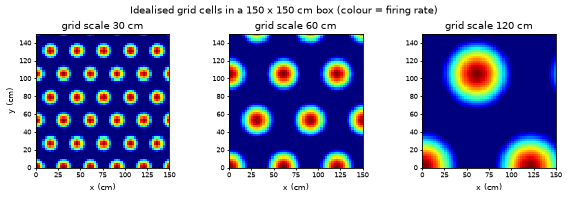

In [2]:
def grid_rate(x, y, scale, orientation_deg=0.0, phase=(0.0, 0.0), peak_hz=15.0):
    """Firing rate of an idealised grid cell (sum of three plane waves, rectified)."""
    k = 4 * np.pi / (np.sqrt(3) * scale)
    g = 0.0
    for j in range(3):
        th = np.deg2rad(orientation_deg + 30 + 60 * j)
        g = g + np.cos(k * ((x - phase[0]) * np.cos(th) + (y - phase[1]) * np.sin(th)))
    return peak_hz * np.maximum(g, 0.0) / 3.0


xs = np.arange(0, 150, 2.5)
X, Y = np.meshgrid(xs, xs)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, s in zip(axes, [30, 60, 120]):
    ax.imshow(grid_rate(X, Y, s), origin="lower", extent=(0, 150, 0, 150), cmap="jet",
              interpolation="nearest")
    ax.set_title(f"grid scale {s} cm")
    ax.set_xlabel("x (cm)")
axes[0].set_ylabel("y (cm)")
plt.suptitle("Idealised grid cells in a 150 x 150 cm box (colour = firing rate)")
plt.tight_layout()
plt.show()

## Step 2: the agent (simulated rat + grid cells)

The agent follows NeuralPlayground's agent interface: `act(obs)` receives the rat's position from the arena and returns a movement. Inside `act`, the agent:

1. **Moves** with a bounded random walk like the paper's simulated rats: speed and heading drift randomly, speed stays between 0 and 40 cm/s, and the rat picks a new direction when a wall blocks it.
2. **Senses walls**: if it is within 12 cm of a wall, that wall becomes the "last wall touched". This plays the role of **border cells**, neurons that fire when the animal is next to a wall.
3. **Re-anchors its grids** (the tethering rule). The grid fires as if the rat were in the familiar box, at the same distance from the last wall touched. For example, after touching the west wall, a point 20 cm from the west wall fires like the point 20 cm from the west wall in the familiar box. The walls that run along the deformation (north and south here) changed length, so for them the grid is anchored to the centre, a simplifying assumption.

Setting `tethered=False` gives a control agent whose grid stays centred and never re-anchors.

Each module has 8 grid cells with random positions (phases). Grid scales follow the roughly 1.4× steps between modules seen in rats: 30, 42, 60, 85 and 120 cm.

One simplification: I use 20 ms time steps (50 Hz, a typical tracking rate) instead of the paper's 3 ms, so the notebook runs quickly. The noise in speed and heading is scaled to match.

In [3]:
class BoundaryTetheredGridAgent(AgentCore):
    """Simulated rat carrying grid modules whose phase is re-anchored to the last wall touched.

    Implements the boundary-tethered rule of Keinath, Epstein & Balasubramanian (2018):
    whenever the rat comes within ``contact_cm`` of a wall, every grid takes the phase it
    had relative to that wall in the familiar box.

    Parameters
    ----------
    familiar_limits : array-like, shape (2, 2)
        [[x_min, x_max], [y_min, y_max]] of the familiar box in cm.
    scales : sequence of float
        Grid scale (cm) of each module.
    cells_per_module : int
        Number of grid cells per module, each with a random spatial phase.
    tethered : bool
        If False, the grid stays centred and never re-anchors (control).
    dt : float
        Time step in seconds.
    contact_cm : float
        Distance from a wall that counts as touching it (12 cm in the paper).
    seed : int
        Random seed for the walk and the grid phases.

    Attributes
    ----------
    positions, walls, rates : list
        Position, last wall touched (0 = west, 1 = east, 2 = south, 3 = north,
        -1 = none yet) and firing rate of every cell (Hz) at each step.
    """

    def __init__(self, familiar_limits, scales=(30, 42, 60, 85, 120), cells_per_module=8,
                 tethered=True, dt=0.02, contact_cm=12.0, seed=0,
                 agent_name="BoundaryTetheredGrid", **mod_kwargs):
        super().__init__(agent_name=agent_name, **mod_kwargs)
        self.familiar_limits = np.asarray(familiar_limits, float)
        self.scales = np.asarray(scales, float)
        self.cells_per_module = cells_per_module
        self.tethered = tethered
        self.dt = dt
        self.contact_cm = contact_cm
        self.rng = np.random.default_rng(seed)
        # one row per grid cell: its module's scale and a random spatial phase
        self.cell_scale = np.repeat(self.scales, cells_per_module)
        self.cell_phase = self.rng.uniform(0, 150, size=(len(self.cell_scale), 2))
        k = 4 * np.pi / (np.sqrt(3) * self.cell_scale)
        th = np.deg2rad(30 + 60 * np.arange(3))
        self.kx = k[:, None] * np.cos(th)[None, :]          # (cells, 3 waves)
        self.ky = k[:, None] * np.sin(th)[None, :]
        self.reset()

    def reset(self, arena_limits=None):
        super().reset()
        self.arena_limits = (self.familiar_limits if arena_limits is None
                             else np.asarray(arena_limits, float))
        self.speed, self.heading = 0.0, self.rng.uniform(-np.pi, np.pi)
        self.last_wall, self.last_pos, self.intended = -1, None, None
        self.positions, self.walls, self.rates = [], [], []

    def _update_last_wall(self, pos):
        (x0, x1), (y0, y1) = self.arena_limits
        d = np.array([pos[0] - x0, x1 - pos[0], pos[1] - y0, y1 - pos[1]])
        # d: distance to the west, east, south and north walls (wall codes 0-3)
        if d.min() < self.contact_cm:
            self.last_wall = int(d.argmin())

    def _familiar_coords(self, pos):
        """Where the grid 'thinks' the rat is in the familiar box (the tethering rule)."""
        (x0, x1), (y0, y1) = self.arena_limits
        (fx0, fx1), (fy0, fy1) = self.familiar_limits
        # default: centre-aligned
        x = pos[0] - (x0 + x1) / 2 + (fx0 + fx1) / 2
        y = pos[1] - (y0 + y1) / 2 + (fy0 + fy1) / 2
        if self.tethered:
            w = self.last_wall
            if w == 0: x = pos[0] - x0 + fx0      # keep distance to west wall
            if w == 1: x = pos[0] - x1 + fx1      # keep distance to east wall
            if w == 2: y = pos[1] - y0 + fy0      # keep distance to south wall
            if w == 3: y = pos[1] - y1 + fy1      # keep distance to north wall
        return x, y

    def act(self, obs):
        pos = np.asarray(obs, float)
        # 1. if the last step was blocked by a wall, pick a new random heading
        if self.last_pos is not None and self.intended is not None:
            moved = np.linalg.norm(pos - self.last_pos)
            if moved < 0.9 * np.linalg.norm(self.intended):
                self.heading = self.rng.uniform(-np.pi, np.pi)
        # 2. border signal + grid firing at the current position
        self._update_last_wall(pos)
        fx, fy = self._familiar_coords(pos)
        dx, dy = fx - self.cell_phase[:, :1], fy - self.cell_phase[:, 1:]
        rates = 15.0 * np.maximum(np.cos(self.kx * dx + self.ky * dy).sum(1), 0) / 3.0
        self.positions.append(pos)
        self.walls.append(self.last_wall)
        self.rates.append(rates)
        # 3. bounded random walk (speed and heading drift randomly)
        self.speed = float(np.clip(self.speed + self.rng.normal(0, 2.6), 0, 40))
        self.heading += self.rng.normal(0, np.deg2rad(11.6))
        step = self.speed * self.dt
        self.intended = step * np.array([np.cos(self.heading), np.sin(self.heading)])
        self.last_pos = pos
        self.global_steps += 1
        return self.intended

    def results(self):
        return np.array(self.positions), np.array(self.walls), np.array(self.rates)

## Step 3: familiar and deformed boxes in NeuralPlayground

`Simple2D` builds a rectangular arena and stops the agent from walking through walls. The familiar box is 150 × 150 cm; the deformed box is compressed east–west to 100 × 150 cm. Coordinates are in cm, centred on the box.

I run three 30-minute sessions with the same random seed:
- the familiar box,
- the deformed box with re-anchoring (`tethered=True`),
- the deformed box without re-anchoring (control).

familiar                     90000 steps


deformed                     90000 steps


deformed, no re-anchoring    90000 steps


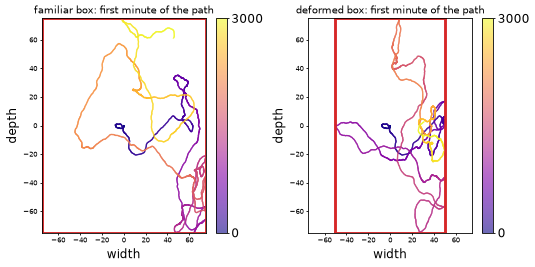

In [4]:
def run_session(agent, arena_limits, minutes=30, dt=0.02):
    env = Simple2D(arena_x_limits=tuple(arena_limits[0]), arena_y_limits=tuple(arena_limits[1]),
                   time_step_size=dt, agent_step_size=1.0)
    centre = [np.mean(arena_limits[0]), np.mean(arena_limits[1])]
    obs, state = env.reset(custom_state=centre)
    agent.reset(arena_limits)
    for _ in range(int(minutes * 60 / dt)):
        action = agent.act(obs)
        obs, state, reward = env.step(action)
    return env, agent.results()


FAMILIAR = np.array([[-75, 75], [-75, 75]])
DEFORMED = np.array([[-50, 50], [-75, 75]])

sessions = {}
for name, limits, tethered in [("familiar", FAMILIAR, True),
                               ("deformed", DEFORMED, True),
                               ("deformed, no re-anchoring", DEFORMED, False)]:
    agent = BoundaryTetheredGridAgent(FAMILIAR, tethered=tethered, seed=1)
    env, (pos, walls, rates) = run_session(agent, limits, minutes=30)
    sessions[name] = dict(env=env, pos=pos, walls=walls, rates=rates, limits=limits)
    print(f"{name:28s} {len(pos)} steps")

SCALES = agent.scales
N_CELLS = agent.cells_per_module

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, name in zip(axes, ["familiar", "deformed"]):
    sessions[name]["env"].plot_trajectory(history_data=sessions[name]["env"].history[:3000], ax=ax)
    ax.set_title(f"{name} box: first minute of the path")
plt.tight_layout()
plt.show()

## Step 4: analysis tools (following the paper's Methods)

- **Rate map**: average firing rate in 2.5 cm × 2.5 cm pixels, smoothed with a Gaussian (σ = 1.5 pixels).
- **Cross-correlation**: how similar two maps are when one is slid over the other. Among the slides that give a good match, the one closest to no slide at all tells us how far one grid pattern is shifted relative to the other.
- **Apparent rescaling**: stretch or squash the familiar map to several widths and find which width best matches the deformed map. 0 means the map did not rescale; 1 means it rescaled exactly as much as the box. Following the paper, the stretched map is aligned by the west and east walls. I also allow alignment by the centre: without it, a grid that simply stays centred is scored as up to about 80% rescaled.

For simplicity I use the cells' firing *rates* directly instead of simulating random spikes, so the maps are noise-free. Real recordings are much noisier.

In [5]:
BIN = 2.5


def rate_map(pos, rate, limits, mask=None, sigma_px=1.5):
    (x0, x1), (y0, y1) = limits
    nx, ny = int(round((x1 - x0) / BIN)), int(round((y1 - y0) / BIN))
    if mask is not None:
        pos, rate = pos[mask], rate[mask]
    ix = np.clip(((pos[:, 0] - x0) / BIN).astype(int), 0, nx - 1)
    iy = np.clip(((pos[:, 1] - y0) / BIN).astype(int), 0, ny - 1)
    idx = iy * nx + ix
    occ = np.bincount(idx, minlength=nx * ny).astype(float)
    tot = np.bincount(idx, weights=rate, minlength=nx * ny)
    m = np.full(nx * ny, np.nan)
    m[occ > 0] = tot[occ > 0] / occ[occ > 0]
    m = m.reshape(ny, nx)
    r = np.arange(9) - 4
    k = np.exp(-(r[:, None] ** 2 + r[None, :] ** 2) / (2 * sigma_px ** 2))
    k /= k.sum()
    v = np.isfinite(m)
    num = convolve(np.where(v, m, 0), k, mode="constant")
    den = convolve(v.astype(float), k, mode="constant")
    out = np.full(m.shape, np.nan)
    out[v] = num[v] / den[v]
    return out


def pearson(a, b):
    v = np.isfinite(a) & np.isfinite(b)
    x, y = a[v] - a[v].mean(), b[v] - b[v].mean()
    return float((x * y).sum() / np.sqrt((x * x).sum() * (y * y).sum()))


def xcorr(a, b, min_overlap=20):
    """Correlation between maps a and b at every spatial shift (only overlapping pixels)."""
    f = lambda u, w: fftconvolve(u, w[::-1, ::-1])
    ma, mb = np.isfinite(a) * 1.0, np.isfinite(b) * 1.0
    a0, b0 = np.nan_to_num(a), np.nan_to_num(b)
    n = np.rint(f(ma, mb))
    sa, sb, saa, sbb, sab = f(a0, mb), f(ma, b0), f(a0 ** 2, mb), f(ma, b0 ** 2), f(a0, b0)
    with np.errstate(all="ignore"):
        r = (sab - sa * sb / n) / np.sqrt((saa - sa ** 2 / n) * (sbb - sb ** 2 / n))
    r[n < min_overlap] = np.nan
    return r, (b.shape[0] - 1, b.shape[1] - 1)


def shift_between(map_a, map_b, scale):
    """East-west shift (cm) between two maps: peak of their cross-correlation nearest zero lag."""
    r, (cy, cx) = xcorr(map_a, map_b)
    h = int(np.ceil(scale / 2 / BIN))
    win = r[cy - h: cy + h + 1, cx - h: cx + h + 1]
    lab, n = label(np.nan_to_num(win, nan=-1) > 0)
    if n == 0:
        return np.nan
    yy, xx = np.indices(win.shape)
    dist = np.hypot(yy - h, xx - h)
    k = min(range(1, n + 1), key=lambda i: dist[lab == i].min())
    py, px = np.unravel_index(np.argmax(np.where(lab == k, win, -np.inf)), win.shape)
    return abs(px - h) * BIN


def apparent_rescaling(fam_map, def_map, fam_len, def_len):
    """How much the familiar map must be stretched along x to best match the deformed map:
    0 = no rescaling, 1 = stretched exactly as much as the box. Following the paper, the
    stretched familiar map is aligned by the west and by the east wall; I also allow
    alignment by the centre, otherwise a grid that simply stays centred looks rescaled."""
    best = (-np.inf, None)
    for L in np.arange(min(fam_len, def_len) - 10, max(fam_len, def_len) + 10.1, 5):
        n_out = int(round(L / BIN))
        zf = zoom(np.nan_to_num(fam_map), (1, n_out / fam_map.shape[1]), order=1)[:, :n_out]
        m = min(n_out, def_map.shape[1])
        oa, ob = (zf.shape[1] - m) // 2, (def_map.shape[1] - m) // 2
        for a, b in ((zf[:, :m], def_map[:, :m]), (zf[:, -m:], def_map[:, -m:]),
                     (zf[:, oa:oa + m], def_map[:, ob:ob + m])):
            r = pearson(a, b)
            if r > best[0]:
                best = (r, L)
    return (best[1] / fam_len - 1) / (def_len / fam_len - 1)


def predicted_shift(scale, delta):
    """Shift between west- and east-anchored grids along x (grid axis along x)."""
    s = (delta + scale / 2) % scale - scale / 2
    return abs(s)

## Result 1: averaged maps of large grids look rescaled

Below, one cell from each module: its map in the familiar box (top) and its whole-session map in the compressed box (bottom). White pixels are places the rat never visited. The grid's true size never changes, yet from 42 cm upwards fields smear or appear doubled, because the pattern jumps between two positions depending on which wall the rat touched last. Whether the whole map *looks* squashed depends on the grid's size, which Result 3 measures.

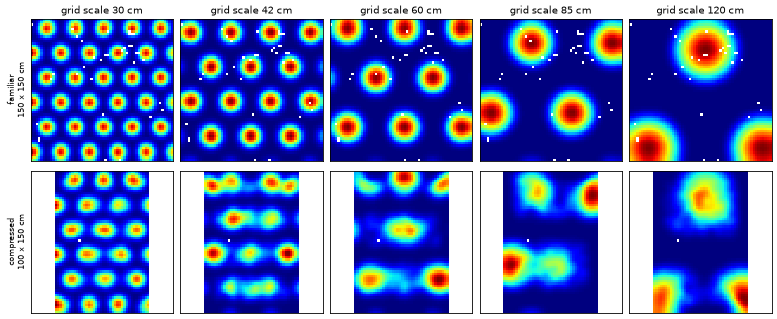

In [6]:
fam, dfm = sessions["familiar"], sessions["deformed"]
fig, axes = plt.subplots(2, len(SCALES), figsize=(13, 5.5),
                         gridspec_kw={"width_ratios": [1] * len(SCALES)})
for m, s in enumerate(SCALES):
    c = m * N_CELLS                                     # first cell of module m
    axes[0, m].imshow(rate_map(fam["pos"], fam["rates"][:, c], FAMILIAR),
                      origin="lower", cmap="jet", extent=(-75, 75, -75, 75),
                      interpolation="nearest")
    axes[1, m].imshow(rate_map(dfm["pos"], dfm["rates"][:, c], DEFORMED),
                      origin="lower", cmap="jet", extent=(-50, 50, -75, 75),
                      interpolation="nearest")
    axes[0, m].set_title(f"grid scale {s:.0f} cm")
for ax in axes.ravel():
    ax.set_xlim(-75, 75); ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("familiar\n150 x 150 cm")
axes[1, 0].set_ylabel("compressed\n100 x 150 cm")
plt.tight_layout()
plt.show()

## Result 2: splitting by the last wall touched reveals the jump

This is the paper's key analysis. In the compressed box, I make one map from the moments after the rat touched the **west** wall and another from the moments after it touched the **east** wall. If the grid re-anchors, the two maps are shifted relative to each other. Each map only covers the places the rat visited after that wall, so parts of it are white (unvisited).

How big should the shift be? The box shrank by 50 cm. A west-anchored and an east-anchored grid are offset by 50 cm, but because the pattern repeats every *scale* cm, the visible shift is 50 cm wrapped into one repeat. For example, a 42 cm grid shifted by 50 cm looks shifted by only 8 cm. Without re-anchoring, the shift should be 0.

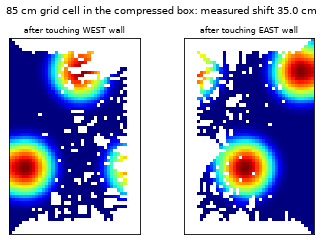

grid scale | predicted | re-anchoring | control   (shift in cm, median of 8 cells)
        30 |      10.0 |         10.0 |     0.0
        42 |       8.0 |          7.5 |     0.0
        60 |      10.0 |         10.0 |     0.0
        85 |      35.0 |         35.0 |     0.0
       120 |      50.0 |         52.5 |     0.0


In [7]:
def wall_split_shift(sess, cell, scale):
    p, w, r, lim = sess["pos"], sess["walls"], sess["rates"][:, cell], sess["limits"]
    west = rate_map(p, r, lim, mask=(w == 0))
    east = rate_map(p, r, lim, mask=(w == 1))
    return west, east, shift_between(west, east, scale)

# example: one 85 cm cell
c = 3 * N_CELLS
west, east, sh = wall_split_shift(dfm, c, SCALES[3])
fig, axes = plt.subplots(1, 2, figsize=(6, 4))
for ax, mp, t in zip(axes, [west, east], ["after touching WEST wall", "after touching EAST wall"]):
    ax.imshow(mp, origin="lower", cmap="jet", extent=(-50, 50, -75, 75),
                      interpolation="nearest")
    ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"85 cm grid cell in the compressed box: measured shift {sh:.1f} cm")
plt.tight_layout()
plt.show()

# all modules, tethered vs control
rows = []
for m, s in enumerate(SCALES):
    cells = range(m * N_CELLS, (m + 1) * N_CELLS)
    teth = np.median([wall_split_shift(dfm, c, s)[2] for c in cells])
    ctrl = np.median([wall_split_shift(sessions["deformed, no re-anchoring"], c, s)[2] for c in cells])
    rows.append((s, predicted_shift(s, 50), teth, ctrl))
print(f"{'grid scale':>10} | {'predicted':>9} | {'re-anchoring':>12} | {'control':>7}   (shift in cm, median of 8 cells)")
for s, p, t, c in rows:
    print(f"{s:10.0f} | {p:9.1f} | {t:12.1f} | {c:7.1f}")

The measured shifts match the prediction for every module, and the control shows no shift. This is the signature Keinath et al. found in real rat grid cells (their Figs. 1–2).

## Result 3: whether a grid *looks* rescaled depends on its size

Now the main point of the paper. For each cell I measure the apparent rescaling of its whole-session map in the compressed box (0 = none, 1 = matched to the box).

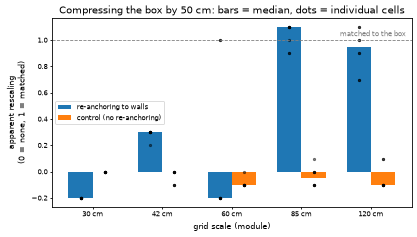

grid scale | re-anchoring | control   (apparent rescaling, median of 8 cells)
        30 |        -0.20 |    0.00
        42 |         0.30 |    0.00
        60 |        -0.20 |   -0.10
        85 |         1.10 |   -0.05
       120 |         0.95 |   -0.10


In [8]:
resc = {"deformed": [], "deformed, no re-anchoring": []}
for m, s in enumerate(SCALES):
    for key in resc:
        vals = []
        for c in range(m * N_CELLS, (m + 1) * N_CELLS):
            f_map = rate_map(fam["pos"], fam["rates"][:, c], FAMILIAR)
            sess = sessions[key]
            d_map = rate_map(sess["pos"], sess["rates"][:, c], DEFORMED)
            vals.append(apparent_rescaling(f_map, d_map, 150, 100))
        resc[key].append(vals)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(SCALES))
for k, (key, col, lab) in enumerate([("deformed", "tab:blue", "re-anchoring to walls"),
                                     ("deformed, no re-anchoring", "tab:orange", "control (no re-anchoring)")]):
    v = np.array(resc[key])
    ax.bar(x + (k - 0.5) * 0.35, np.median(v, axis=1), 0.35, color=col, label=lab)
    ax.scatter(np.repeat(x + (k - 0.5) * 0.35, N_CELLS), v.ravel(), s=8, color="k", alpha=0.5)
ax.axhline(1, ls="--", c="gray", lw=1)
ax.text(len(SCALES) - 0.5, 1.03, "matched to the box", ha="right", fontsize=8, color="gray")
ax.set_xticks(x, [f"{s:.0f} cm" for s in SCALES])
ax.set_xlabel("grid scale (module)")
ax.set_ylabel("apparent rescaling\n(0 = none, 1 = matched)")
ax.set_title("Compressing the box by 50 cm: bars = median, dots = individual cells")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'grid scale':>10} | {'re-anchoring':>12} | {'control':>7}   (apparent rescaling, median of 8 cells)")
for m, s in enumerate(SCALES):
    print(f"{s:10.0f} | {np.median(resc['deformed'][m]):12.2f} | "
          f"{np.median(resc['deformed, no re-anchoring'][m]):7.2f}")

With re-anchoring, the small grids (30–60 cm) mostly do not look rescaled (medians between −0.2 and 0.3, although two of the eight 60 cm cells are scored as fully rescaled), while the large grids (85 and 120 cm) look rescaled almost exactly as much as the box. The control never looks rescaled. (A value of −0.2 is the edge of the search range: the best match was the familiar map *stretched* by 10 cm, meaning squashing it never helped. The measure moves in 5 cm steps, i.e. 0.1 on this scale.) One rule, re-anchoring to the last wall touched, produces both "rescaling" and "non-rescaling" modules, even though no grid ever changed its true size. This is the paper's central claim, reproduced here without any neural network.

Why does size matter? A wall can only reset the grid to within one repeat of its pattern, so the west- and east-anchored grids are offset by the 50 cm deformation wrapped into one repeat. For the small grids that offset is only 8–10 cm: averaging blurs the fields slightly, but the pattern keeps its spacing. For the large grids the offset is 35–50 cm, a large part of the pattern, and the average looks like a squashed grid.

## Limitations and notes

- **No network.** Re-anchoring is imposed directly, like the paper's no-network simulation (Fig. 5—figure supplement 2). The paper also shows that a spiking network, in which border cells learn connections to grid cells, produces the same behaviour.
- **Idealised cells.** Firing rates are noise-free and grids are perfect hexagons. Real cells are noisier, which makes the shifts harder to measure.
- **Re-anchoring is all-or-nothing here.** In my review of the paper I argue that the shifts measured in real cells (their Fig. 2A) are smaller than full re-anchoring would predict, suggesting the anchoring is only partial. This notebook does not model partial anchoring.
- **Centre alignment.** I added centre alignment to the rescaling measure (see Step 4), which the paper does not use.
- **Time step.** 20 ms steps instead of 3 ms, for speed.
- **North and south walls** are assumed to anchor the grid to the centre of the box, because they changed length.

## References

- Keinath, A. T., Epstein, R. A., & Balasubramanian, V. (2018). Environmental deformations dynamically shift the grid cell spatial metric. *eLife*, 7, e38169.
- Bush, D., Barry, C., & Burgess, N. (2014). What do grid cells contribute to place cell firing? *Trends in Neurosciences*, 37, 136–145.
- Stensola, H., Stensola, T., Solstad, T., Frøland, K., Moser, M.-B., & Moser, E. I. (2012). The entorhinal grid map is discretized. *Nature*, 492, 72–78.